In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter, PercentFormatter, StrMethodFormatter

from datasets import DEPENDENT, INDEPENDENT


use_tex = True


# some stolen code
plt.rcParams.update({
    # Text & Font settings
    'text.usetex': use_tex,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'] if use_tex else ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'axes.unicode_minus': False,
    'pdf.fonttype': 42,
    
    # Sizing
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'legend.fontsize': 6.5,
    'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5,
    
    # Spines & Ticks
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    
    # Grid
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.5,
    
    # Lines & Plotting
    'lines.linewidth': 0.9,
    'lines.markersize': 2.5,
    'errorbar.capsize': 1.5,
    
    # Figure & Export
    'figure.dpi': 200,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.01
})

In [100]:
COLUMN_WIDTH = 3.2

# easier this way to split the plots later on
POINT = ['NB', 'NB(1)', 'TAN', 'NPC', 'FNB']
PROBABILISTIC = ['NB', 'NB(1)', 'TAN', 'FNB']
CREDAL = ['NCC', 'TANC']
MODELS = POINT + CREDAL

TIMED = [model for model in MODELS if model != 'NB(1)']

DATASETS = ['Synthetic independent', 'Synthetic dependent', 'Iris']
SYNTHETIC = DATASETS[:2]

TITLES = {'Synthetic independent': 'Independent', 'Synthetic dependent': 'Dependent', 'Iris': 'Iris'}

COLORS = dict(zip(MODELS, plt.rcParams['axes.prop_cycle'].by_key()['color']))
MARKERS = dict(zip(MODELS, 'osDv^ph'))

BAYES = {'Synthetic independent': INDEPENDENT.max(axis=0).sum() / 2, 'Synthetic dependent': DEPENDENT.max(axis=0).sum() / 2}

RESULTS, FIGURES, TABLES = Path('results'), Path('figures'), Path('tables')
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

summary = pd.read_csv(RESULTS / 'summary.csv', index_col=['dataset', 'n_train', 'classifier'])
timings = pd.read_csv(RESULTS / 'timings.csv', index_col=['dataset', 'n_train', 'classifier'])
n_seeds = len(json.loads((RESULTS / 'metadata.json').read_text())['seeds'])

In [101]:
def training_sizes(dataset):
    return summary.xs(dataset).index.get_level_values('n_train').unique().sort_values()


def plot_models(ax, dataset, models, metric, spread, **style):
    
    for model, offset in zip(models, np.linspace(-spread / 2, spread / 2, len(models))):
        data = summary.xs((dataset, model), level=('dataset', 'classifier')).sort_index()
        x = np.arange(len(data)) + offset

        ax.errorbar(x, data[metric], data[metric + '_se'], color=COLORS[model], marker=MARKERS[model], elinewidth=.6, capthick=.6, **style)


def legend(fig, bayes=False):
    handles = [Line2D([], [], color=COLORS[model], marker=MARKERS[model], label=model) for model in POINT]

    if bayes: handles.append(Line2D([], [], color='.4', linestyle=':', label='Bayes accuracy'))

    handles += [Line2D([], [], color=COLORS[model], marker=MARKERS[model], label=model) for model in CREDAL]
    handles.append(Line2D([], [], color='.4', marker='o', label='One-label rate'))
    handles.append(Line2D([], [], color='.4', marker='o', linestyle='--', markerfacecolor='white', label='Coverage'))

    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .98), ncol=4, frameon=False, handlelength=2, columnspacing=1)

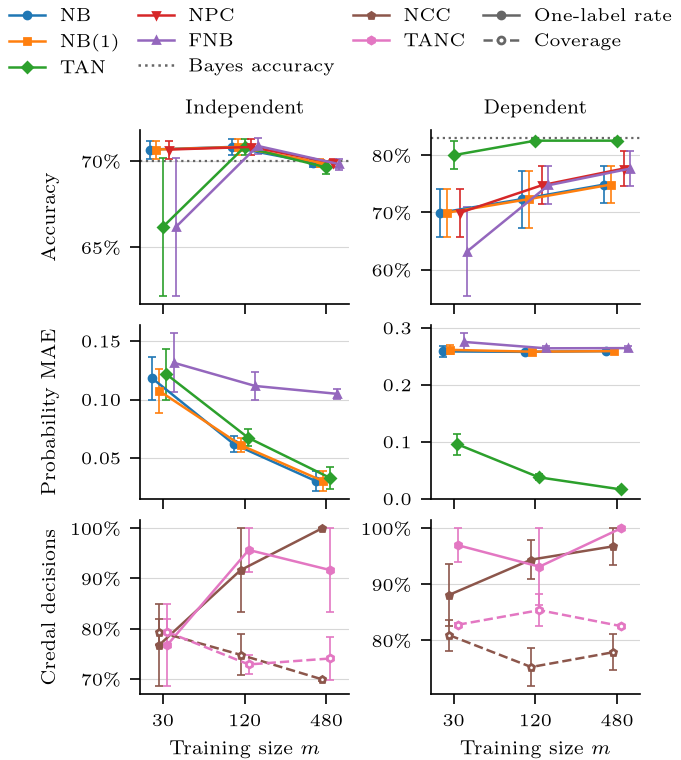

In [102]:
fig, axes = plt.subplots(3, 2, figsize=(COLUMN_WIDTH, 3.5), sharex=True)

for c, dataset in enumerate(SYNTHETIC):
    axes[0, c].set_title(TITLES[dataset])
    axes[0, c].axhline(BAYES[dataset], color='.4', linestyle=':', linewidth=.8)

    plot_models(axes[0, c], dataset, POINT, 'accuracy', .32)
    plot_models(axes[1, c], dataset, PROBABILISTIC, 'probability_mae', .26)
    plot_models(axes[2, c], dataset, CREDAL, 'singleton_rate', .1)
    plot_models(axes[2, c], dataset, CREDAL, 'coverage', .1, linestyle='--', markerfacecolor='white')

    axes[2, c].set_xticks(range(3), training_sizes(dataset))
    axes[2, c].set_xlabel('Training size $m$')

for ax in [*axes[0], *axes[2]]:
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

axes[0, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylabel('Probability MAE')
axes[2, 0].set_ylabel('Credal decisions')

fig.align_ylabels(axes[:, 0])
fig.tight_layout(h_pad=.4, w_pad=.6)
legend(fig, bayes=True)
fig.savefig(FIGURES / 'synthetic.pdf')
plt.show()

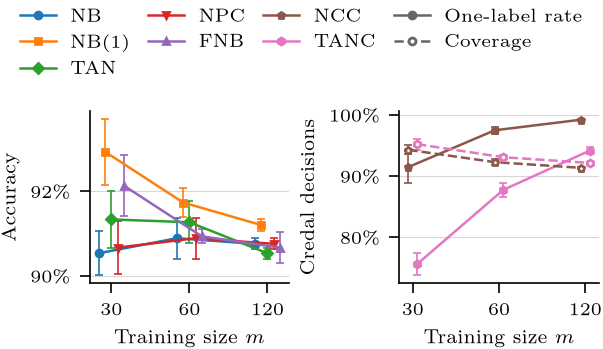

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(COLUMN_WIDTH, 1.4))

plot_models(axes[0], 'Iris', POINT, 'accuracy', .32)
plot_models(axes[1], 'Iris', CREDAL, 'singleton_rate', .1)
plot_models(axes[1], 'Iris', CREDAL, 'coverage', .1, linestyle='--', markerfacecolor='white')

for ax in axes:
    ax.set_xticks(range(3), training_sizes('Iris'))
    ax.set_xlabel('Training size $m$')
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

axes[0].set_ylabel('Accuracy')
axes[1].set_ylabel('Credal decisions')

fig.tight_layout(w_pad=.6)
legend(fig)
fig.savefig(FIGURES / 'iris.pdf')
plt.show()

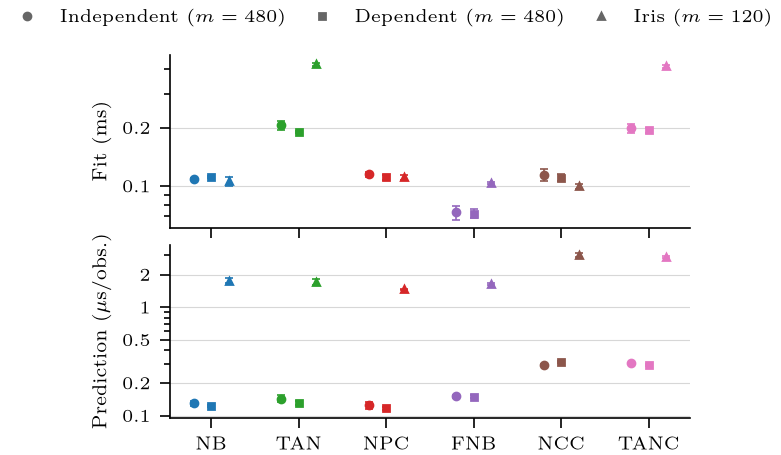

In [104]:
DATASET_MARKERS = {'Synthetic independent': 'o', 'Synthetic dependent': 's', 'Iris': '^'}
largest = {dataset: training_sizes(dataset).max() for dataset in DATASETS}
labels = {'fit_ms': 'Fit (ms)', 'predict_us': r'Prediction ($\mu$s/obs.)'}

fig, axes = plt.subplots(2, 1, figsize=(COLUMN_WIDTH, 2.2), sharex=True)

for ax, (metric, label) in zip(axes, labels.items()):
    for i, model in enumerate(TIMED):
        for offset, dataset in zip((-.2, 0, .2), DATASETS):
            row = timings.loc[(dataset, largest[dataset], model)]
            ax.errorbar(i + offset, row[metric], row[metric + '_se'], color=COLORS[model], marker=DATASET_MARKERS[dataset], elinewidth=.6, capthick=.6)

    ax.set_yscale('log')
    ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_ylabel(label)

axes[1].set_xticks(range(len(TIMED)), TIMED)

handles = [Line2D([], [], color='.4', marker=marker, linestyle='none', label=f'{TITLES[dataset]} ($m={largest[dataset]}$)') for dataset, marker in DATASET_MARKERS.items()]

fig.align_ylabels(axes)
fig.tight_layout(h_pad=.4)
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .98), ncol=3, frameon=False, columnspacing=1)
fig.savefig(FIGURES / 'timings.pdf')
plt.show()

In [105]:
latex_tables = {}


def mean_se(metric, scale=1, digits=2, data=summary):
    mean, se = data[metric] * scale, data[metric + '_se'] * scale
    cells = mean.map(f'{{:.{digits}f}}'.format) + ' ± ' + se.map(f'{{:.{digits}f}}'.format)

    return cells.where(mean.notna(), '–')


def wide(cells, models, datasets=DATASETS):
    table = cells.unstack(['dataset', 'n_train']).loc[models, datasets].rename(columns=TITLES, level='dataset')
    table.index.name, table.columns.names = None, [None, 'm']

    return table

In [106]:
table = wide(mean_se('accuracy', scale=100), POINT)
latex_tables['point_accuracy'] = (table, 'Point accuracy (\\%).')
table

Independent                                 Dependent                \
m               30            120           480           30            120   
NB     70.66 ± 0.52  70.81 ± 0.47  69.90 ± 0.24  69.96 ± 4.18  72.33 ± 4.99   
NB(1)  70.66 ± 0.52  70.81 ± 0.47  69.90 ± 0.24  69.96 ± 4.18  72.33 ± 4.99   
TAN    66.18 ± 4.01  70.81 ± 0.47  69.62 ± 0.35  80.00 ± 2.48  82.54 ± 0.22   
NPC    70.66 ± 0.52  70.81 ± 0.47  69.90 ± 0.24  69.96 ± 4.18  74.75 ± 3.36   
FNB    66.18 ± 4.01  70.87 ± 0.46  69.81 ± 0.31  63.13 ± 7.75  74.75 ± 3.36   

                             Iris                              
m               480           30            60            120  
NB     74.86 ± 3.29  90.53 ± 0.52  90.89 ± 0.49  90.76 ± 0.13  
NB(1)  74.86 ± 3.29  92.93 ± 0.78  91.73 ± 0.34  91.20 ± 0.13  
TAN    82.54 ± 0.22  91.33 ± 0.67  91.27 ± 0.50  90.53 ± 0.13  
NPC    77.66 ± 3.09  90.67 ± 0.62  90.89 ± 0.49  90.76 ± 0.13  
FNB    77.66 ± 3.09  92.13 ± 0.71  90.93 ± 0.16  90.67 ± 0.37

In [107]:
table = wide(mean_se('probability_mae', digits=3), PROBABILISTIC, SYNTHETIC)
latex_tables['probability_mae'] = (table, 'Probability MAE on the synthetic data')
table

Independent                                    Dependent  \
m                30             120            480            30    
NB     0.118 ± 0.018  0.062 ± 0.007  0.030 ± 0.009  0.259 ± 0.010   
NB(1)  0.107 ± 0.019  0.061 ± 0.006  0.030 ± 0.008  0.262 ± 0.008   
TAN    0.122 ± 0.022  0.067 ± 0.007  0.033 ± 0.009  0.096 ± 0.019   
FNB    0.132 ± 0.025  0.112 ± 0.012  0.105 ± 0.004  0.276 ± 0.015   

                                     
m                120            480  
NB     0.258 ± 0.001  0.259 ± 0.001  
NB(1)  0.259 ± 0.001  0.260 ± 0.001  
TAN    0.038 ± 0.005  0.017 ± 0.003  
FNB    0.264 ± 0.003  0.265 ± 0.003

In [108]:
table = wide(mean_se('zero_score_rate', scale=100), POINT)
latex_tables['zero_score_rate'] = (table, 'Test observations with zero scores for all classes (\\%)')
table

Independent                              Dependent               \
m              30           120          480          30           120   
NB     0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   
NB(1)  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   
TAN    0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   
NPC    0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   
FNB    0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00   

                           Iris                            
m              480          30           60           120  
NB     0.00 ± 0.00  2.80 ± 0.53  1.07 ± 0.16  0.67 ± 0.00  
NB(1)  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  
TAN    0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  
NPC    0.00 ± 0.00  2.80 ± 0.53  1.07 ± 0.16  0.67 ± 0.00  
FNB    0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00  0.00 ± 0.00

In [109]:
columns = {'singleton_rate': 'One-label rate', 'singleton_accuracy': 'Acc. one-label', 'coverage': 'Coverage'}

table = pd.DataFrame({label: mean_se(metric, scale=100) for metric, label in columns.items()})
table['Mean size'] = mean_se('mean_size')

table = table.reorder_levels(['dataset', 'classifier', 'n_train']).sort_index().loc[DATASETS]
table = table[table.index.get_level_values('classifier').isin(CREDAL)].rename(index=TITLES, level='dataset')
table.index.names = ['Dataset', 'Method', 'm']

latex_tables['credal_decisions'] = (table, 'Credal decisions')
table

One-label rate Acc. one-label      Coverage  \
Dataset     Method m                                                 
Independent NCC    30    76.68 ± 8.16   73.09 ± 1.10  79.37 ± 2.55   
                   120   91.65 ± 8.35   73.50 ± 2.78  74.80 ± 4.06   
                   480  100.00 ± 0.00   69.90 ± 0.24  69.90 ± 0.24   
            TANC   30    76.68 ± 8.16   73.09 ± 1.10  79.37 ± 2.55   
                   120   95.67 ± 4.33   71.79 ± 0.86  72.88 ± 1.89   
                   480   91.65 ± 8.35   72.77 ± 2.94  74.07 ± 4.23   
Dependent   NCC    30    88.14 ± 5.53   78.43 ± 2.29  80.91 ± 2.72   
                   120   94.40 ± 3.43   73.74 ± 3.68  75.25 ± 3.44   
                   480   96.76 ± 3.24   77.24 ± 2.96  77.88 ± 3.18   
            TANC   30    96.98 ± 3.02   82.21 ± 0.34  82.78 ± 0.37   
                   120   93.14 ± 6.86   85.03 ± 2.46  85.39 ± 2.81   
                   480  100.00 ± 0.00   82.54 ± 0.22  82.54 ± 0.22   
Iris        NCC    30    91.47 ± 2.67   93.80 ± 0.68  94.27 ± 0.75   
                   60    97.47 ± 0.53   92.07 ± 0.43  92.27 ± 0.45   
                   120   99.20 ± 0.13   91.26 ± 0.20  91.33 ± 0.21   
            TANC   30    75.60 ± 1.85   93.74 ± 1.07  95.20 ± 0.90   
                   60    87.73 ± 1.20   92.11 ± 0.28  93.07 ± 0.34   
                   120   94.13 ± 0.53   91.64 ± 0.15  92.13 ± 0.13   

                          Mean size  
Dataset     Method m                 
Independent NCC    30   1.23 ± 0.08  
                   120  1.08 ± 0.08  
                   480  1.00 ± 0.00  
            TANC   30   1.23 ± 0.08  
                   120  1.04 ± 0.04  
                   480  1.08 ± 0.08  
Dependent   NCC    30   1.12 ± 0.06  
                   120  1.06 ± 0.03  
                   480  1.03 ± 0.03  
            TANC   30   1.03 ± 0.03  
                   120  1.07 ± 0.07  
                   480  1.00 ± 0.00  
Iris        NCC    30   1.11 ± 0.03  
                   60   1.04 ± 0.01  
                   120  1.01 ± 0.00  
            TANC   30   1.40 ± 0.02  
                   60   1.18 ± 0.01  
                   120  1.10 ± 0.01

In [110]:
blocks = {}

for reference in CREDAL:
    own = mean_se('singleton_accuracy', scale=100).xs(reference, level='classifier').rename('Credal')
    point = mean_se(f'accuracy_on_{reference}_singletons', scale=100).unstack('classifier')[POINT]
    blocks[reference] = pd.concat([own, point], axis=1)

table = pd.concat(blocks, names=['subset']).reorder_levels(['dataset', 'n_train', 'subset']).sort_index().loc[DATASETS]
table = table.rename(index=TITLES, level='dataset')
table.index.names = ['Dataset', 'm', 'One label from']

latex_tables['accuracy_on_credal_singletons'] = (table, 'Accuracy (\\%) on the test observations where NCC or TANC returns one label')
table

Credal            NB         NB(1)  \
Dataset     m   One label from                                             
Independent 30  NCC             73.09 ± 1.10  73.09 ± 1.10  73.09 ± 1.10   
                TANC            73.09 ± 1.10  73.09 ± 1.10  73.09 ± 1.10   
            120 NCC             73.50 ± 2.78  73.50 ± 2.78  73.50 ± 2.78   
                TANC            71.79 ± 0.86  71.79 ± 0.86  71.79 ± 0.86   
            480 NCC             69.90 ± 0.24  69.90 ± 0.24  69.90 ± 0.24   
                TANC            72.77 ± 2.94  72.96 ± 2.88  72.96 ± 2.88   
Dependent   30  NCC             78.43 ± 2.29  78.43 ± 2.29  78.43 ± 2.29   
                TANC            82.21 ± 0.34  72.17 ± 4.75  72.17 ± 4.75   
            120 NCC             73.74 ± 3.68  73.74 ± 3.68  73.74 ± 3.68   
                TANC            85.03 ± 2.46  72.10 ± 5.18  72.10 ± 5.18   
            480 NCC             77.24 ± 2.96  77.24 ± 2.96  77.24 ± 2.96   
                TANC            82.54 ± 0.22  74.86 ± 3.29  74.86 ± 3.29   
Iris        30  NCC             93.80 ± 0.68  93.80 ± 0.68  93.80 ± 0.68   
                TANC            93.74 ± 1.07  93.74 ± 1.07  93.74 ± 1.07   
            60  NCC             92.07 ± 0.43  92.07 ± 0.43  92.07 ± 0.43   
                TANC            92.11 ± 0.28  92.11 ± 0.28  92.11 ± 0.28   
            120 NCC             91.26 ± 0.20  91.26 ± 0.20  91.26 ± 0.20   
                TANC            91.64 ± 0.15  91.64 ± 0.15  91.64 ± 0.15   

                                         TAN           NPC           FNB  
Dataset     m   One label from                                            
Independent 30  NCC             73.09 ± 1.10  73.09 ± 1.10  73.09 ± 1.10  
                TANC            73.09 ± 1.10  73.09 ± 1.10  73.09 ± 1.10  
            120 NCC             73.50 ± 2.78  73.50 ± 2.78  73.56 ± 2.76  
                TANC            71.79 ± 0.86  71.79 ± 0.86  71.85 ± 0.83  
            480 NCC             69.62 ± 0.35  69.90 ± 0.24  69.81 ± 0.31  
                TANC            72.77 ± 2.94  72.96 ± 2.88  72.96 ± 2.88  
Dependent   30  NCC             78.43 ± 2.29  78.43 ± 2.29  67.68 ± 6.96  
                TANC            82.21 ± 0.34  72.17 ± 4.75  65.34 ± 8.52  
            120 NCC             82.00 ± 0.38  73.74 ± 3.68  73.74 ± 3.68  
                TANC            85.03 ± 2.46  75.78 ± 3.01  75.78 ± 3.01  
            480 NCC             82.12 ± 0.51  77.24 ± 2.96  77.24 ± 2.96  
                TANC            82.54 ± 0.22  77.66 ± 3.09  77.66 ± 3.09  
Iris        30  NCC             93.80 ± 0.68  93.80 ± 0.68  93.49 ± 0.54  
                TANC            93.74 ± 1.07  93.74 ± 1.07  93.74 ± 1.07  
            60  NCC             91.73 ± 0.50  92.07 ± 0.43  91.52 ± 0.43  
                TANC            92.11 ± 0.28  92.11 ± 0.28  91.65 ± 0.42  
            120 NCC             90.59 ± 0.20  91.26 ± 0.20  90.59 ± 0.36  
                TANC            91.64 ± 0.15  91.64 ± 0.15  90.93 ± 0.17

In [111]:
table = wide(mean_se('fit_ms', digits=3, data=timings), TIMED)
latex_tables['fit_time'] = (table, 'Fit time (ms)')
table

Independent                                    Dependent  \
m               30             120            480            30    
NB    0.057 ± 0.006  0.060 ± 0.000  0.109 ± 0.001  0.052 ± 0.003   
TAN   0.111 ± 0.013  0.112 ± 0.000  0.205 ± 0.011  0.103 ± 0.007   
NPC   0.066 ± 0.010  0.063 ± 0.001  0.115 ± 0.003  0.067 ± 0.009   
FNB   0.044 ± 0.001  0.047 ± 0.001  0.073 ± 0.006  0.046 ± 0.002   
NCC   0.047 ± 0.001  0.057 ± 0.001  0.114 ± 0.008  0.053 ± 0.007   
TANC  0.100 ± 0.007  0.111 ± 0.002  0.199 ± 0.011  0.116 ± 0.010   

                                             Iris                 \
m               120            480            30             60    
NB    0.062 ± 0.002  0.111 ± 0.001  0.086 ± 0.008  0.086 ± 0.003   
TAN   0.126 ± 0.012  0.190 ± 0.003  0.399 ± 0.008  0.383 ± 0.006   
NPC   0.065 ± 0.001  0.111 ± 0.004  0.088 ± 0.003  0.090 ± 0.001   
FNB   0.046 ± 0.001  0.072 ± 0.004  0.097 ± 0.002  0.098 ± 0.002   
NCC   0.058 ± 0.001  0.111 ± 0.004  0.077 ± 0.003  0.077 ± 0.001   
TANC  0.127 ± 0.011  0.194 ± 0.005  0.404 ± 0.033  0.389 ± 0.016   

                     
m               120  
NB    0.106 ± 0.006  
TAN   0.424 ± 0.008  
NPC   0.111 ± 0.003  
FNB   0.104 ± 0.001  
NCC   0.100 ± 0.003  
TANC  0.414 ± 0.007

In [112]:
table = wide(mean_se('predict_us', digits=3, data=timings), TIMED)
latex_tables['prediction_time'] = (table, 'Prediction time ($\\mu$s per test observation)')
table

Independent                                    Dependent  \
m               30             120            480            30    
NB    0.143 ± 0.009  0.120 ± 0.000  0.129 ± 0.006  0.125 ± 0.002   
TAN   0.132 ± 0.006  0.125 ± 0.004  0.143 ± 0.011  0.141 ± 0.006   
NPC   0.134 ± 0.007  0.125 ± 0.006  0.125 ± 0.009  0.137 ± 0.013   
FNB   0.145 ± 0.004  0.146 ± 0.008  0.150 ± 0.006  0.144 ± 0.003   
NCC   0.317 ± 0.015  0.293 ± 0.004  0.295 ± 0.005  0.318 ± 0.012   
TANC  0.328 ± 0.009  0.316 ± 0.008  0.303 ± 0.005  0.321 ± 0.015   

                                             Iris                 \
m               120            480            30             60    
NB    0.122 ± 0.003  0.123 ± 0.002  1.675 ± 0.036  1.646 ± 0.041   
TAN   0.143 ± 0.007  0.131 ± 0.005  1.760 ± 0.071  1.630 ± 0.021   
NPC   0.114 ± 0.001  0.117 ± 0.004  1.529 ± 0.038  1.454 ± 0.037   
FNB   0.137 ± 0.001  0.150 ± 0.004  1.873 ± 0.085  1.638 ± 0.028   
NCC   0.299 ± 0.005  0.310 ± 0.006  3.161 ± 0.127  2.880 ± 0.065   
TANC  0.324 ± 0.014  0.294 ± 0.005  3.485 ± 0.467  2.944 ± 0.099   

                     
m               120  
NB    1.755 ± 0.090  
TAN   1.712 ± 0.113  
NPC   1.456 ± 0.023  
FNB   1.636 ± 0.025  
NCC   3.026 ± 0.142  
TANC  2.902 ± 0.048

In [113]:
for name, (table, caption) in latex_tables.items():
    latex = table.map(lambda cell: cell.replace(' ± ', r' $\pm$ ').replace('–', '--'))
    caption = f'{caption} Mean $\\pm$ standard error across {n_seeds} seeds'
    column_format = 'l' * table.index.nlevels + 'r' * table.shape[1]

    latex.to_latex(TABLES / f'{name}.tex', caption=caption, label=f'tab:{name}', escape=False, column_format=column_format, multirow=False, multicolumn_format='c')

In [114]:
runs = pd.read_csv(RESULTS / 'runs.csv')
rows = {}
for reference, base in (('NCC', 'NB(1)'), ('TANC', 'TAN')):
    key = f'accuracy_on_{reference}_singletons'

    seeds = (runs[runs.classifier == base].groupby(['dataset', 'n_train', 'seed'])[['point_correct_expected', 'n_test', key + '_correct', key + '_n']].sum())
    
    seeds['one_label_rate'] = seeds[key + '_n'] / seeds['n_test']
    seeds['acc_one_label'] = seeds[key + '_correct'] / seeds[key + '_n']
    
    seeds['acc_set'] = ((seeds['point_correct_expected'] - seeds[key + '_correct']) / (seeds['n_test'] - seeds[key + '_n']).replace(0, np.nan))
    
    rows[(reference, base)] = (seeds.loc['Iris'].groupby('n_train')[['one_label_rate', 'acc_one_label', 'acc_set']].agg(['mean', 'sem']) * 100)

table = pd.concat(rows, names=['Credal', 'Point model'])
table.round(1).to_latex(TABLES / 'credal_set_split.tex')
table.round(1)

one_label_rate      acc_one_label      acc_set  \
                                     mean  sem          mean  sem    mean   
Credal Point model n_train                                                  
NCC    NB(1)       30                91.5  2.7          93.8  0.7    82.6   
                   60                97.5  0.5          92.1  0.4    84.3   
                   120               99.2  0.1          91.3  0.2    90.0   
TANC   TAN         30                75.6  1.8          93.7  1.1    84.8   
                   60                87.7  1.2          92.1  0.3    84.6   
                   120               94.1  0.5          91.6  0.1    72.3   

                                  
                             sem  
Credal Point model n_train        
NCC    NB(1)       30        5.7  
                   60        6.7  
                   120      10.0  
TANC   TAN         30        3.2  
                   60        3.6  
                   120       2.5